## Project 2: Industrial Applied Statistics
Correlation Analysis on Quiz Score and the Total Time Spent in Answering the Quiz

Please upload your dataset (CSV or Excel file):


Saving quiz_history.csv to quiz_history.csv
Source: recorded grade column in Sheet1 (Excel) or CSV.
Sheet2 has a different grading scale; it is not used.
Grade ranks (ordinal, not scores): {'F': 0, 'D': 1, 'C': 2, 'B': 3, 'A': 4, 'A+': 5}
Primary analysis: two-sided Spearman rank correlation.
P-values: 49,999 pairings permutations, fixed random seed 123.
Alpha = 0.05 per category; p-values are not adjusted for multiple tests.
A non-significant result does not establish that correlation is absent.
Lines are descriptive least-squares fits to ordinal codes, not Spearman fits.
Observations must be independent within each category; no causal inference.
Rows excluded for missing/unsupported category: 0

 category  n  excluded_rows  spearman_rho  permutation_p  slope_grade_ranks_per_second  intercept                                                                       conclusion
        1 10              0      0.577387        0.08252                      0.019009  -2.747384 No statistically

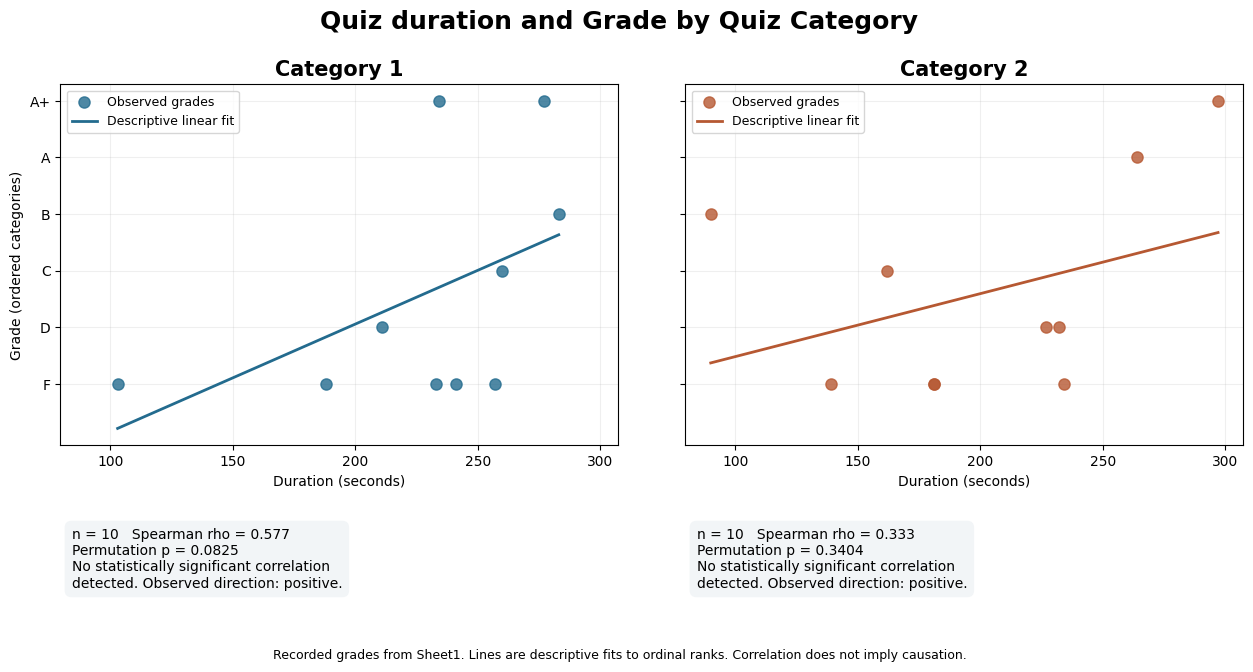

In [ ]:
import sys
from pathlib import Path
import argparse
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

# Ordered lowest to highest. Only observed labels appear on the graph.
GRADE_ORDER = ['F', 'D-', 'D', 'D+', 'C-', 'C', 'C+',
               'B-', 'B', 'B+', 'A-', 'A', 'A+']
ALPHA = 0.05

def run_interactive():
    print("Please upload your dataset (CSV or Excel file):")
    uploaded = files.upload()
    if not uploaded:
        print("No file uploaded. Aborting.")
        return
    file_name = list(uploaded.keys())[0]
    output_dir = Path.cwd() / 'results'
    analyze(file_name, output_dir, show=True)

def analyze(file_path, output_dir, show=True):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    file_path = Path(file_path)
    df = (pd.read_csv(file_path) if file_path.suffix.lower() == '.csv'
          else pd.read_excel(file_path, sheet_name='Sheet1'))
    df.columns = df.columns.astype(str).str.strip()
    required = {'category', 'duration_seconds', 'grade'}
    if not required.issubset(df.columns):
        raise ValueError(f'Missing columns: {sorted(required - set(df.columns))}')
    df['category'] = pd.to_numeric(df['category'], errors='coerce')
    df['duration_seconds'] = pd.to_numeric(df['duration_seconds'], errors='coerce')
    df['grade'] = df['grade'].astype('string').str.strip().str.upper()
    unknown = set(df['grade'].dropna()) - set(GRADE_ORDER)
    if unknown:
        raise ValueError(f'Unrecognized grades: {sorted(unknown)}. Edit GRADE_ORDER.')
    observed = [g for g in GRADE_ORDER if g in set(df['grade'].dropna())]
    mapping = {g: rank for rank, g in enumerate(observed)}
    df['grade_rank'] = df['grade'].map(mapping)
    invalid_category = int((~df['category'].isin([1, 2])).sum())
    notes = [
        'Source: recorded grade column in Sheet1 (Excel) or CSV.',
        'Sheet2 has a different grading scale; it is not used.',
        f'Grade ranks (ordinal, not scores): {mapping}',
        'Primary analysis: two-sided Spearman rank correlation.',
        'P-values: 49,999 pairings permutations, fixed random seed 123.',
        'Alpha = 0.05 per category; p-values are not adjusted for multiple tests.',
        'A non-significant result does not establish that correlation is absent.',
        'Lines are descriptive least-squares fits to ordinal codes, not Spearman fits.',
        'Observations must be independent within each category; no causal inference.',
        f'Rows excluded for missing/unsupported category: {invalid_category}',
    ]
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.8), sharex=True, sharey=True)
    records = []
    for ax, category, color in zip(axes, [1, 2], ['#236B8E', '#B65832']):
        group = df.loc[df['category'] == category]
        valid = (group[['duration_seconds', 'grade_rank']].notna().all(axis=1)
                 & np.isfinite(group['duration_seconds'])
                 & (group['duration_seconds'] >= 0))
        clean = group.loc[valid]
        x = clean['duration_seconds'].to_numpy(dtype=float)
        y = clean['grade_rank'].to_numpy(dtype=float)
        row = dict(category=category, n=len(clean), excluded_rows=int((~valid).sum()),
                   spearman_rho=np.nan, permutation_p=np.nan,
                   slope_grade_ranks_per_second=np.nan, intercept=np.nan)
        ax.scatter(x, y, color=color, s=65, alpha=0.8, label='Observed grades')
        if len(x) < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
            conclusion = 'Correlation undefined: insufficient data or a constant variable.'
            annotation = f'n = {len(x)}\n{conclusion}'
        else:
            xr, yr = stats.rankdata(x), stats.rankdata(y)
            xc, yc = xr - xr.mean(), yr - yr.mean()
            denominator = np.linalg.norm(xc) * np.linalg.norm(yc)

            def statistic(permuted_y, axis=-1):
                return np.sum(xc * permuted_y, axis=axis) / denominator

            rho = float(stats.spearmanr(x, y).statistic)
            test = stats.permutation_test(
                (yc,), statistic, permutation_type='pairings',
                vectorized=True, n_resamples=49999, batch=2000,
                alternative='two-sided', rng=np.random.default_rng(123))
            p = float(test.pvalue)
            fit = stats.linregress(x, y)
            xx = np.linspace(x.min(), x.max(), 100)
            ax.plot(xx, fit.intercept + fit.slope * xx, color=color,
                    linewidth=2, label='Descriptive linear fit')
            direction = 'positive' if rho > 0 else 'negative' if rho < 0 else 'zero'
            if p < ALPHA:
                conclusion = f'Statistically significant {direction} correlation.'
            else:
                conclusion = (f'No statistically significant correlation detected. '
                              f'Observed direction: {direction}.')
            row.update(spearman_rho=rho, permutation_p=p,
                       slope_grade_ranks_per_second=fit.slope, intercept=fit.intercept)
            annotation = (f'n = {len(x)}   Spearman rho = {rho:.3f}\n'
                          f'Permutation p = {p:.4f}\n'
                          + textwrap.fill(conclusion, 49))
        row['conclusion'] = conclusion
        records.append(row)
        ax.set_title(f'Category {category}', fontsize=15, weight='bold')
        ax.set_xlabel('Duration (seconds)')
        ax.set_yticks(range(len(observed)), observed)
        ax.grid(alpha=0.2)
        ax.set_axisbelow(True)
        ax.legend(loc='upper left', fontsize=9)
        ax.text(0.02, -0.23, annotation, transform=ax.transAxes, fontsize=10,
                va='top', bbox=dict(boxstyle='round,pad=0.5', fc='#F2F5F7', ec='none'))
    axes[0].set_ylabel('Grade (ordered categories)')
    fig.suptitle('Quiz duration and Grade by Quiz Category', fontsize=18, weight='bold')
    fig.text(0.5, 0.025,
             'Recorded grades from Sheet1. Lines are descriptive fits to ordinal ranks. '
             'Correlation does not imply causation.', ha='center', fontsize=9)
    fig.subplots_adjust(left=0.07, right=0.98, top=0.87, bottom=0.34, wspace=0.12)
    fig.savefig(output_dir / 'correlation_by_category.png', dpi=220)
    summary = pd.DataFrame(records)
    summary.to_csv(output_dir / 'correlation_summary.csv', index=False)
    report = '\n'.join(notes) + '\n\n' + summary.to_string(index=False)
    (output_dir / 'correlation_report.txt').write_text(report, encoding='utf-8')
    print(report)
    print(f'\nResults saved to: {output_dir.resolve()}')
    if show:
        plt.show()
    plt.close(fig)
    return summary

if __name__ == '__main__':
    # Check if running interactively in Google Colab
    if 'google.colab' in sys.modules:
        run_interactive()
    else:
        try:
            script_dir = Path(__file__).resolve().parent
        except NameError:
            script_dir = Path.cwd()
        parser = argparse.ArgumentParser(description=__doc__)
        parser.add_argument('file', nargs='?', default=str(script_dir / 'mockdata.xlsx'))
        parser.add_argument('--output', default=str(script_dir / 'results'))
        parser.add_argument('--no-show', action='store_true', help='Save graph without opening a window')
        args = parser.parse_args()
        analyze(args.file, args.output, show=not args.no_show)